In [1]:
!pip install fg-data-profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.5/400.5 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.3/106.3 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 2.7 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import data_profiling
from data_profiling import ProfileReport
import matplotlib.pyplot as plt
from google.colab import files

In [3]:
# Profile Report to explore data
df = pd.read_csv("/content/drive/MyDrive/master_stock_data.csv")

ProfileReport(df, title="Raw Profile", explorative=True).to_file("raw_profile.html")

files.download("raw_profile.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 10/10 [00:11<00:00,  1.12s/it]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# CLEAN — using what a profile report typically flags
df = df.drop_duplicates()
df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]

In [5]:
# drop columns that are >60% empty (junk/near-empty cols a profiler flags)
df = df.loc[:, df.isna().mean() < 0.6]

for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna("unknown").str.strip()

df.to_csv("cleaned_data.csv", index=False)

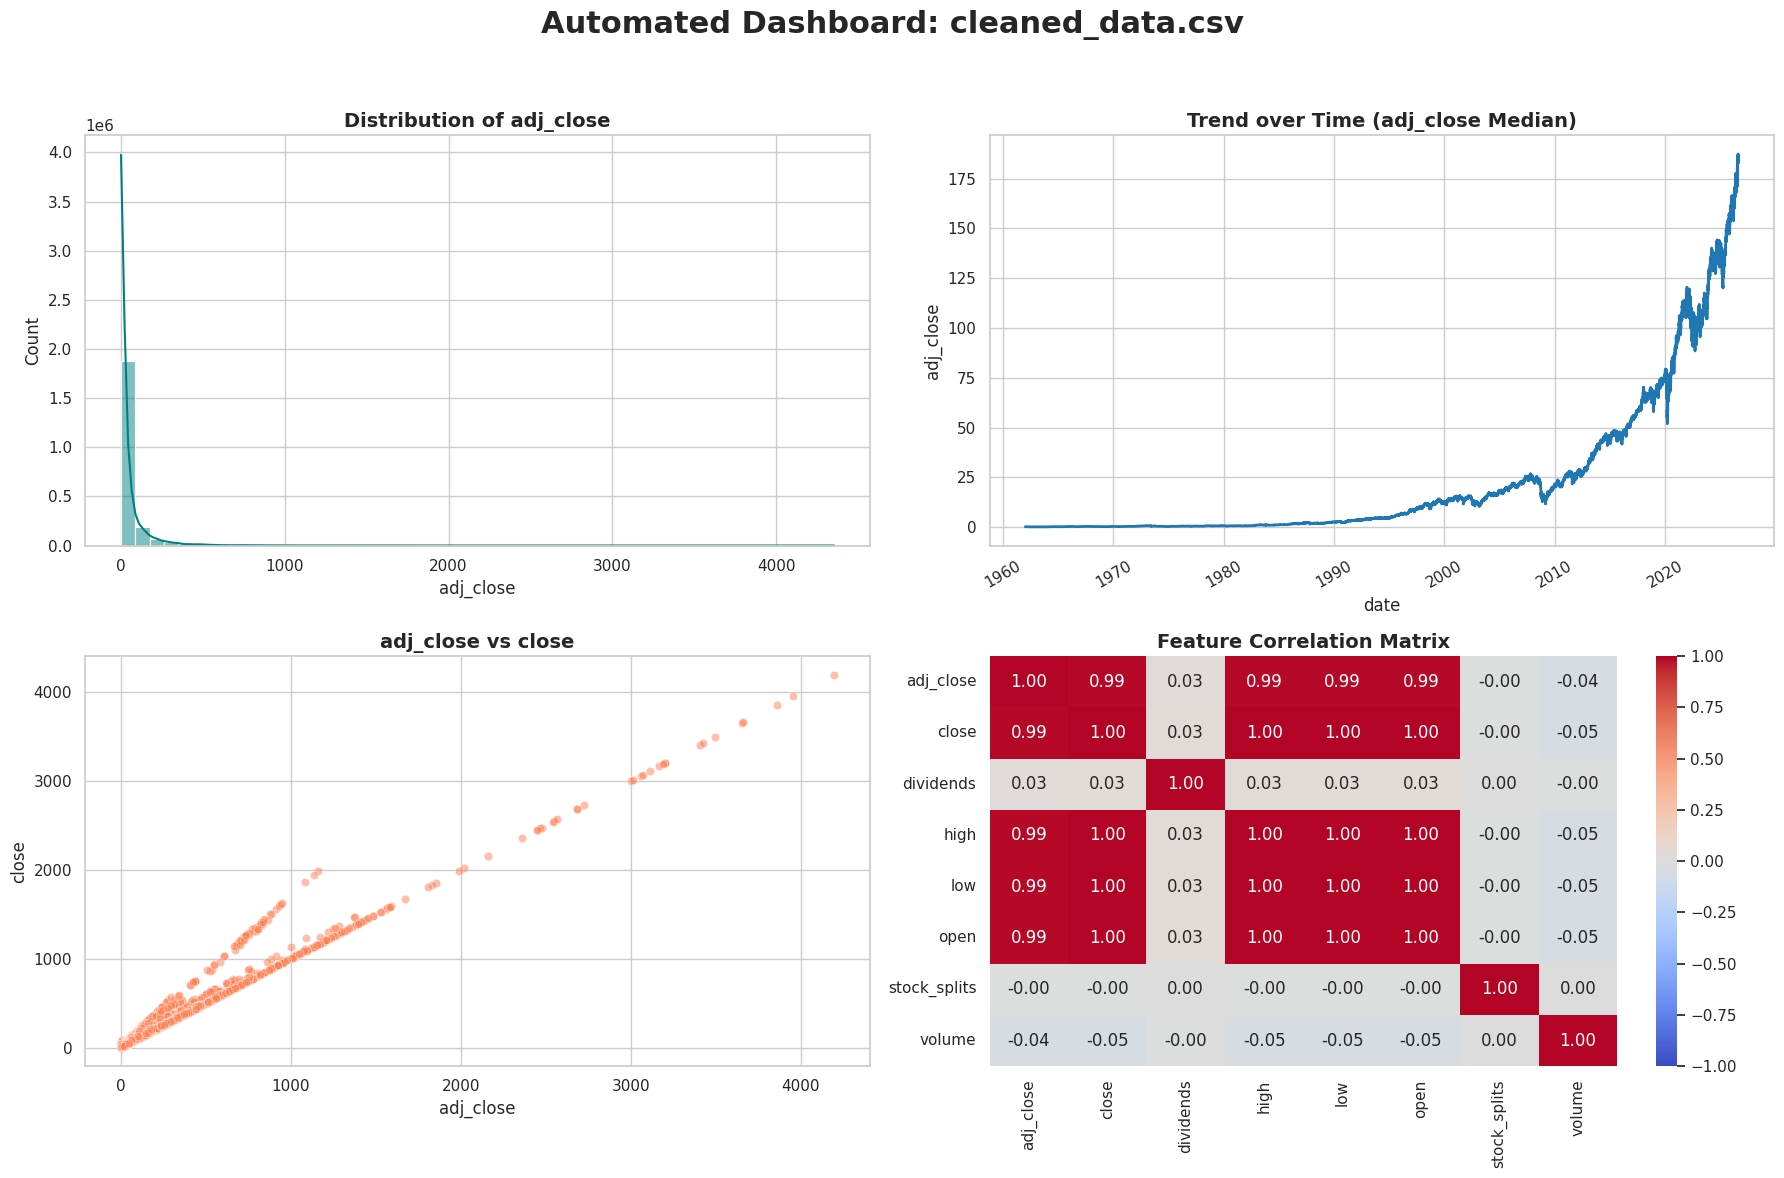

Dashboard successfully saved as universal_dashboard.png.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

def generate_universal_dashboard(file_path="cleaned_data.csv"):
    if not os.path.exists(file_path):
        print(f"File '{file_path}' not found.")
        return

    # Load Data
    df = pd.read_csv(file_path)

    # Identify columns by type
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

    # Try to identify date columns
    date_col = None
    for col in cat_cols:
        if 'date' in col.lower() or 'time' in col.lower():
            try:
                df[col] = pd.to_datetime(df[col])
                date_col = col
                break
            except:
                pass

    # Remove the converted date from categorical lists
    if date_col in cat_cols:
        cat_cols.remove(date_col)

    # Setup visualization theme
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    fig.suptitle(f"Automated Dashboard: {os.path.basename(file_path)}", fontsize=22, weight='bold', y=0.98)

    # Subplot 1: Distribution of the primary numeric column
    if len(num_cols) > 0:
        primary_num = num_cols[0]
        sns.histplot(ax=axes[0, 0], data=df, x=primary_num, bins=50, kde=True, color='teal')
        axes[0, 0].set_title(f'Distribution of {primary_num}', fontsize=14, weight='bold')
    else:
        axes[0, 0].text(0.5, 0.5, 'No Numeric Data Available', ha='center', va='center', fontsize=14)

    # Subplot 2: Categorical Frequency or Trend Over Time
    if date_col and len(num_cols) > 0:
        primary_num = num_cols[0]
        # Resample daily median
        daily_trend = df.groupby(date_col)[primary_num].median().reset_index()
        sns.lineplot(ax=axes[0, 1], x=date_col, y=primary_num, data=daily_trend, color='#1f77b4', linewidth=2)
        axes[0, 1].set_title(f'Trend over Time ({primary_num} Median)', fontsize=14, weight='bold')
        axes[0, 1].tick_params(axis='x', rotation=30)
    elif len(cat_cols) > 0:
        primary_cat = cat_cols[0]
        top_categories = df[primary_cat].value_counts().head(8).reset_index()
        top_categories.columns = [primary_cat, 'count']
        sns.barplot(ax=axes[0, 1], x=primary_cat, y='count', data=top_categories, hue=primary_cat, palette='viridis', legend=False)
        axes[0, 1].set_title(f'Top Categories in {primary_cat}', fontsize=14, weight='bold')
        axes[0, 1].tick_params(axis='x', rotation=30)
    else:
        axes[0, 1].text(0.5, 0.5, 'No Time Series or Categorical Data', ha='center', va='center', fontsize=14)

    # Subplot 3: Relationship between Top 2 Numeric Variables (or Category distribution)
    if len(num_cols) >= 2:
        sns.scatterplot(ax=axes[1, 0], data=df.sample(min(len(df), 50000)), x=num_cols[0], y=num_cols[1], alpha=0.5, color='coral')
        axes[1, 0].set_title(f'{num_cols[0]} vs {num_cols[1]}', fontsize=14, weight='bold')
    elif len(num_cols) == 1 and len(cat_cols) > 0:
        sns.boxplot(ax=axes[1, 0], data=df, x=cat_cols[0], y=num_cols[0], palette='Set2')
        axes[1, 0].set_title(f'{num_cols[0]} Distribution by {cat_cols[0]}', fontsize=14, weight='bold')
        axes[1, 0].tick_params(axis='x', rotation=30)
    else:
        axes[1, 0].text(0.5, 0.5, 'Insufficient Data for Relationship Plot', ha='center', va='center', fontsize=14)

    # Subplot 4: Heatmap Correlation
    if len(num_cols) >= 2:
        corr_matrix = df[num_cols[:10]].corr() # limit to top 10 for readability
        sns.heatmap(ax=axes[1, 1], data=corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
        axes[1, 1].set_title('Feature Correlation Matrix', fontsize=14, weight='bold')
    else:
        axes[1, 1].text(0.5, 0.5, 'Incomplete Metrics for Correlation Matrix', ha='center', va='center', fontsize=14)

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    output_image = "universal_dashboard.png"
    plt.savefig(output_image, dpi=300)
    plt.show()
    print(f"Dashboard successfully saved as {output_image}.")
    files.download(output_image)

# Automatically run the dynamic dashboard on 'cleaned_data.csv'
generate_universal_dashboard('cleaned_data.csv')

In [10]:
# Download files

files.download("cleaned_data.csv")
files.download(f"universal_dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>